# Lecture 5: Gradient Descent & Your First Neural Network in PyTorch 🧠

Welcome! In this notebook we go from **zero** to a **working neural network**. You don't need any deep-learning experience, just basic Python and a bit of high-school maths (the slope of a line).

### What you'll learn

| Part | Topic | Tool |
|---|---|---|
| **1** | **Gradient descent**: the algorithm every neural network uses to learn. We build it from scratch so you can see *every single number*. | NumPy |
| **2** | **Autograd**: how PyTorch computes all the derivatives for us automatically. | PyTorch |
| **3** | **A real neural network** that predicts house prices. | PyTorch |
| **4** | **Exercises** that get progressively harder 🟢 → 🟡 → 🔴 | both |

> 💡 **How to use this notebook:** run the cells **in order**, from top to bottom (`Shift + Enter`). Read the text above each cell, run it, then look at the output. Change numbers and re-run as much as you like. You can't break anything!

## 0. Setup

First we import the libraries we need. Every line has a comment saying what the library is for.

In [1]:
import numpy as np                 # numerical computing: arrays, maths
import pandas as pd                # loading tables of data (CSV files)
import matplotlib.pyplot as plt    # plotting

import torch                       # PyTorch: tensors + automatic derivatives
import torch.nn as nn              # neural-network building blocks (layers, loss functions)

# Fix the random seeds so everybody gets the same numbers when running the notebook
np.random.seed(0)
torch.manual_seed(0)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1


---
# Part 1: Gradient descent from scratch (NumPy)

## 1.1 The big idea

Every machine-learning model has:

- **parameters**: numbers the model is allowed to change (for example the slope and intercept of a line, or the weights of a neural network);
- a **loss**: **one single number** that measures *how wrong* the model currently is.

**Learning = finding the parameters that make the loss as small as possible.**

### 🏔️ Analogy: walking down a hill in the fog

Imagine you're standing on a hillside in thick fog and you want to reach the bottom of the valley. You can't see anything, so what do you do?

1. Feel the ground under your feet: **which way is downhill?**
2. Take a **small step** in that direction.
3. **Repeat** until the ground feels flat.

That is gradient descent. The translation is:

| Hill analogy | Machine learning |
|---|---|
| your height | the **loss** |
| your position | the **parameters** |
| the slope under your feet | the **gradient** (derivative) |
| how big your steps are | the **learning rate** |

## 1.2 Quick reminder: what is a derivative?

The derivative $f'(w)$ is the **slope** of the function $f$ at the point $w$:

- $f'(w) > 0$: the function goes **up** as $w$ increases, so to go down we should **decrease** $w$.
- $f'(w) < 0$: the function goes **down** as $w$ increases, so we should **increase** $w$.
- $f'(w) = 0$: the ground is flat, so we are at the bottom (a minimum) 🎉

In every case we move **in the opposite direction of the derivative**. That gives us the famous **gradient descent update rule**:

$$
\boxed{\;w_{\text{new}} = w_{\text{old}} - \eta \cdot f'(w_{\text{old}})\;}
$$

- $\eta$ (the Greek letter "eta") is the **learning rate**: a small positive number, like `0.1`, that controls the step size.
- The **minus sign** is what makes us go *downhill*.

## 1.3 Our first example: minimise $f(w) = (w - 3)^2$

The answer here is obviously $w = 3$: a square is never negative, and it equals $0$ exactly when $w = 3$.

Let's **pretend we don't know that** and let gradient descent find it. For that we need the derivative:

$$
f(w) = (w-3)^2 \quad\Longrightarrow\quad f'(w) = 2\,(w-3)
$$

(Sanity check: at $w = 3$ the derivative is $2 \cdot 0 = 0$, i.e. flat. ✅)

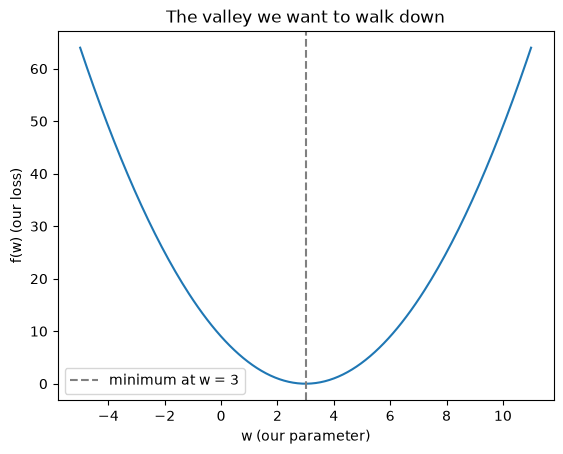

In [2]:
def f(w):
    # The function we want to minimise (our "loss")
    return (w - 3) ** 2

def df(w):
    # Its derivative (the slope at point w)
    return 2 * (w - 3)

# Plot the function so we can see the "valley"
w_values = np.linspace(-5, 11, 200)       # 200 evenly spaced points between -5 and 11
plt.plot(w_values, f(w_values))
plt.axvline(3, color="gray", linestyle="--", label="minimum at w = 3")
plt.xlabel("w (our parameter)")
plt.ylabel("f(w) (our loss)")
plt.title("The valley we want to walk down")
plt.legend()
plt.show()

### One step, by hand

Before writing any loops, let's do **one single step** and look at every number.

In [3]:
w = -4.0              # our starting guess (deliberately bad)
learning_rate = 0.1   # step size

slope = df(w)                    # 1. measure the slope where we are standing
step = learning_rate * slope     # 2. decide how far to move
w_new = w - step                 # 3. move AGAINST the slope

print(f"Starting point:   w = {w}")
print(f"Slope there:      f'(w) = 2 * ({w} - 3) = {slope}")
print(f"Step:             learning_rate * slope = {learning_rate} * {slope} = {step:.1f}")
print(f"New point:        w - step = {w} - ({step:.1f}) = {w_new:.1f}")
print()
print(f"Loss before: f({w}) = {f(w):.2f}")
print(f"Loss after:  f({w_new:.1f}) = {f(w_new):.2f}   <-- smaller, we went downhill!")

Starting point:   w = -4.0
Slope there:      f'(w) = 2 * (-4.0 - 3) = -14.0
Step:             learning_rate * slope = 0.1 * -14.0 = -1.4
New point:        w - step = -4.0 - (-1.4) = -2.6

Loss before: f(-4.0) = 49.00
Loss after:  f(-2.6) = 31.36   <-- smaller, we went downhill!


🔍 **What happened?** The slope at $w=-4$ is **negative** ($-14$), meaning "downhill is to the right". Subtracting a negative number *increases* $w$, so we moved from $-4$ to $-2.6$, closer to $3$. ✅

### Now let's repeat it many times

Gradient descent is just that same step inside a loop.

In [4]:
def gradient_descent_1d(df, w_start, learning_rate, n_steps):
    # Runs gradient descent on a 1-parameter function.
    # Returns the list of all the w values visited (so we can plot the path).
    w = w_start
    history = [w]
    for step in range(n_steps):
        w = w - learning_rate * df(w)     # <-- the whole algorithm is this one line!
        history.append(w)
    return history


history = gradient_descent_1d(df, w_start=-4.0, learning_rate=0.1, n_steps=25)

# Print a small table of what happened
print(f"{'step':>4} | {'w':>8} | {'slope':>8} | {'loss f(w)':>10}")
print("-" * 40)
for i, w in enumerate(history):
    if i < 8 or i == len(history) - 1:       # print the first few + the last
        print(f"{i:>4} | {w:>8.4f} | {df(w):>8.4f} | {f(w):>10.4f}")
    elif i == 8:
        print(" ...")

step |        w |    slope |  loss f(w)
----------------------------------------
   0 |  -4.0000 | -14.0000 |    49.0000
   1 |  -2.6000 | -11.2000 |    31.3600
   2 |  -1.4800 |  -8.9600 |    20.0704
   3 |  -0.5840 |  -7.1680 |    12.8451
   4 |   0.1328 |  -5.7344 |     8.2208
   5 |   0.7062 |  -4.5875 |     5.2613
   6 |   1.1650 |  -3.6700 |     3.3673
   7 |   1.5320 |  -2.9360 |     2.1550
 ...
  25 |   2.9736 |  -0.0529 |     0.0007


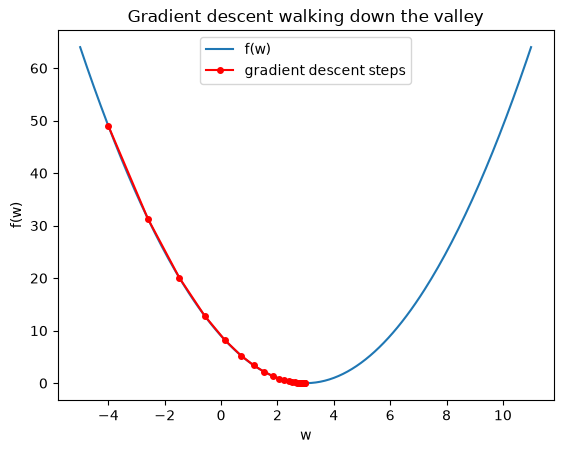

In [5]:
# Visualise the path on top of the curve
history = np.array(history)

plt.plot(w_values, f(w_values), label="f(w)")
plt.plot(history, f(history), "o-", color="red", markersize=4, label="gradient descent steps")
plt.xlabel("w")
plt.ylabel("f(w)")
plt.title("Gradient descent walking down the valley")
plt.legend()
plt.show()

💡 **Notice:** the steps are **big at the start and tiny near the bottom**, even though the learning rate never changed. That's because the *slope* gets smaller as we approach the minimum, so `learning_rate * slope` gets smaller too. The algorithm slows down by itself. Neat!

## 1.4 The learning rate matters a LOT

The learning rate $\eta$ is a **hyperparameter**: a setting *we* choose, not something the model learns. Let's try four different values on the same problem.

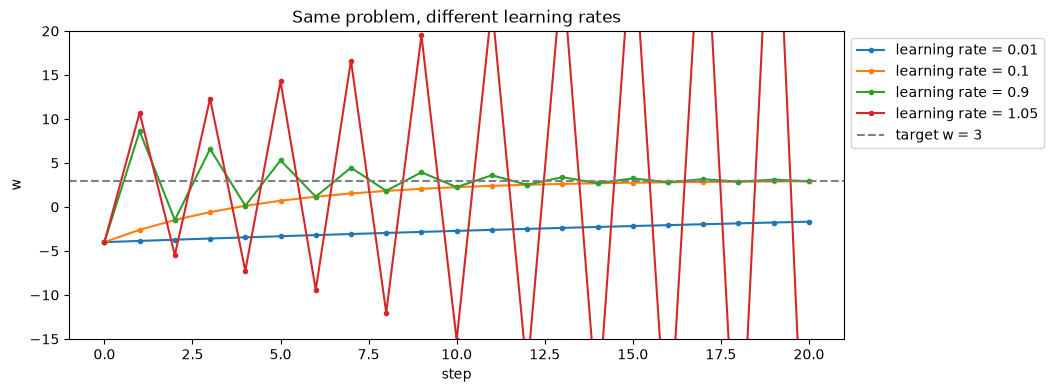

In [6]:
learning_rates = [0.01, 0.1, 0.9, 1.05]

plt.figure(figsize=(10, 4))
for lr in learning_rates:
    path = gradient_descent_1d(df, w_start=-4.0, learning_rate=lr, n_steps=20)
    plt.plot(path, "o-", markersize=3, label=f"learning rate = {lr}")

plt.axhline(3, color="gray", linestyle="--", label="target w = 3")
plt.xlabel("step")
plt.ylabel("w")
plt.ylim(-15, 20)
plt.title("Same problem, different learning rates")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))   # put the legend outside the plot
plt.show()

| Learning rate | What happens |
|---|---|
| `0.01` (too small) | 🐢 Moves in the right direction but **very slowly**. It hasn't arrived after 20 steps. |
| `0.1` (good) | ✅ Gets to $w = 3$ quickly and smoothly. |
| `0.9` (big) | 🏓 **Overshoots**, jumps from one side of the valley to the other, but still slowly settles. |
| `1.05` (too big) | 💥 Every jump is bigger than the last: it **diverges** and never finds the minimum. |

> 🧠 **Takeaway:** if your loss explodes or turns into `nan`, the learning rate is probably too big. If training is painfully slow, it may be too small.

## 1.5 Gradient descent on real data: fitting a line

Now for the real thing. We have some data points $(x_i, y_i)$ and we want to find the line

$$
\hat{y} = w\,x + b
$$

that fits them best. ($\hat{y}$, "y-hat", means *our prediction*.) Now we have **two** parameters: the slope $w$ and the intercept $b$.

We'll create fake data where we *know* the true answer ($w = 3$, $b = 5$), so we can check whether gradient descent finds it.

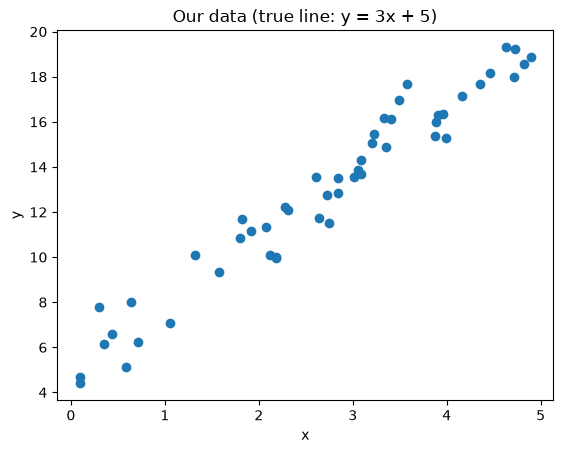

In [7]:
n_points = 50
x = np.random.uniform(0, 5, n_points)              # 50 random x values between 0 and 5
noise = np.random.normal(0, 1, n_points)           # random noise, so the points aren't perfectly on a line
y = 3 * x + 5 + noise                              # the TRUE relationship: w = 3, b = 5

plt.scatter(x, y)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Our data (true line: y = 3x + 5)")
plt.show()

### Step A: choose a loss

We use the **Mean Squared Error (MSE)**: for each point compute the error (prediction minus truth), square it, and average over all $N$ points:

$$
L(w, b) = \frac{1}{N}\sum_{i=1}^{N} \big(\underbrace{w\,x_i + b}_{\hat{y}_i} - y_i\big)^2
$$

- Squaring makes every error positive, so errors above and below the line can't cancel out.
- It also punishes big errors much more than small ones.

### Step B: compute the gradient

With two parameters we need **two derivatives**, one for each parameter. These are called **partial derivatives** ($\partial$ instead of $d$): we differentiate with respect to one parameter while treating the other one as a constant.

Let's do it for **one point** first. Call the error $e = w\,x + b - y$, so the loss for that point is $e^2$. Using the **chain rule** ("derivative of the outside × derivative of the inside"):

$$
\frac{\partial (e^2)}{\partial w} = \underbrace{2e}_{\text{outside}} \cdot \underbrace{\frac{\partial e}{\partial w}}_{=\,x} = 2\,e\,x
\qquad\qquad
\frac{\partial (e^2)}{\partial b} = 2e \cdot \underbrace{\frac{\partial e}{\partial b}}_{=\,1} = 2\,e
$$

Averaging over all the points gives:

$$
\boxed{\frac{\partial L}{\partial w} = \frac{2}{N}\sum_{i=1}^{N} (\hat{y}_i - y_i)\,x_i
\qquad\qquad
\frac{\partial L}{\partial b} = \frac{2}{N}\sum_{i=1}^{N} (\hat{y}_i - y_i)}
$$

🧠 **Does this make sense?** If our predictions are too **high** on average, then $\hat{y}_i - y_i > 0$, so $\frac{\partial L}{\partial b} > 0$, and the update $b \leftarrow b - \eta \cdot (\text{positive})$ **lowers** $b$, which brings the line down. Exactly what we want!

### Step C: the training loop

Each iteration (called an **epoch** when we use all the data once) does **4 steps**. Remember them, because PyTorch will do exactly the same thing later:

1. **Forward pass**: make predictions with the current parameters.
2. **Loss**: measure how wrong they are.
3. **Gradients**: work out which direction makes the loss bigger.
4. **Update**: take a small step in the *opposite* direction.

In [8]:
# Start from a bad guess
w = 0.0
b = 0.0
learning_rate = 0.05
n_epochs = 500

loss_history = []

for epoch in range(n_epochs):
    # 1. FORWARD PASS: predictions for ALL points at once (NumPy does it element-wise)
    y_pred = w * x + b

    # 2. LOSS: mean squared error
    error = y_pred - y
    loss = np.mean(error ** 2)
    loss_history.append(loss)

    # 3. GRADIENTS: the two formulas we derived above
    dL_dw = 2 * np.mean(error * x)
    dL_db = 2 * np.mean(error)

    # 4. UPDATE: step against the gradient
    w = w - learning_rate * dL_dw
    b = b - learning_rate * dL_db

    if epoch % 50 == 0 or epoch == n_epochs - 1:
        print(f"epoch {epoch:>3} | loss = {loss:8.4f} | w = {w:.4f} | b = {b:.4f}")

print(f"\nLearned: w = {w:.3f}, b = {b:.3f}   (true values: w = 3, b = 5)")

epoch   0 | loss = 183.1899 | w = 4.0136 | b = 1.2897
epoch  50 | loss =   1.2923 | w = 3.3722 | b = 3.5578
epoch 100 | loss =   0.9216 | w = 3.1071 | b = 4.4349
epoch 150 | loss =   0.8655 | w = 3.0041 | b = 4.7759
epoch 200 | loss =   0.8570 | w = 2.9640 | b = 4.9085
epoch 250 | loss =   0.8558 | w = 2.9485 | b = 4.9600
epoch 300 | loss =   0.8556 | w = 2.9424 | b = 4.9800
epoch 350 | loss =   0.8555 | w = 2.9400 | b = 4.9878
epoch 400 | loss =   0.8555 | w = 2.9391 | b = 4.9909
epoch 450 | loss =   0.8555 | w = 2.9388 | b = 4.9920
epoch 499 | loss =   0.8555 | w = 2.9386 | b = 4.9925

Learned: w = 2.939, b = 4.992   (true values: w = 3, b = 5)


It found values very close to $w = 3$ and $b = 5$! (They're not *exactly* 3 and 5 because of the random noise we added; with noisy data this is the best line possible.)

Let's look at the result and at how the loss went down during training:

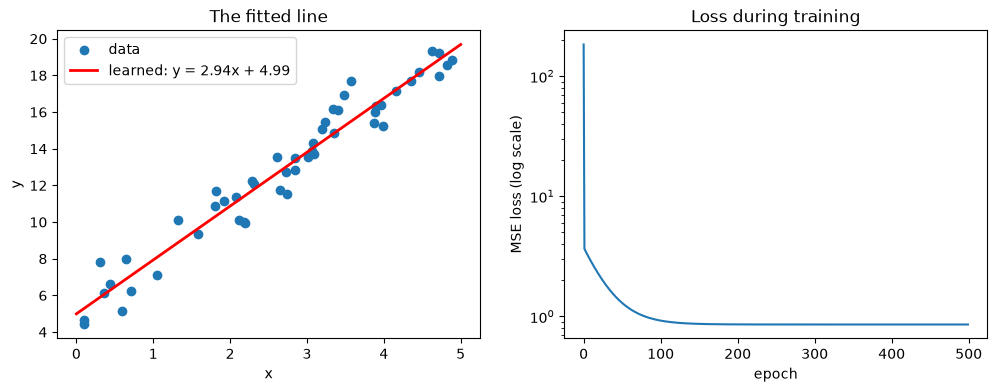

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Left: the data and our learned line
x_line = np.linspace(0, 5, 100)
ax1.scatter(x, y, label="data")
ax1.plot(x_line, w * x_line + b, color="red", linewidth=2, label=f"learned: y = {w:.2f}x + {b:.2f}")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_title("The fitted line")
ax1.legend()

# Right: the loss curve
ax2.plot(loss_history)
ax2.set_yscale("log")          # log scale so we can see both the big early and small late values
ax2.set_xlabel("epoch")
ax2.set_ylabel("MSE loss (log scale)")
ax2.set_title("Loss during training")

plt.show()

📉 **The loss curve** is the most important plot in deep learning. It should go **down** and then flatten out. If it goes up or jumps around wildly, something is wrong (often the learning rate).

## 1.6 From a line to a neuron: the chain rule

A **neuron** is just our line with one extra ingredient. It:

1. multiplies each input by a weight and adds them up, plus a bias: $z = x_0 w_0 + x_1 w_1 + x_2 w_2 + b$ (a line, but with 3 inputs);
2. passes the result through an **activation function**. The most popular one is **ReLU**:

$$
\text{ReLU}(z) = \max(0, z) \qquad \text{(negative numbers become 0, positive numbers stay the same)}
$$

Here is a neuron with 3 inputs. Green numbers are the values flowing **forward** through it:

<img src="nn.png" alt="A single neuron: inputs times weights, summed with bias, then ReLU" width="700"/>

In [10]:
# The exact numbers from the picture
x_n = np.array([1.0, -2.0, 3.0])    # inputs
w_n = np.array([-3.0, -1.0, 2.0])   # weights
b_n = 1.0                           # bias

# Forward pass, one piece at a time
products = x_n * w_n                # [1*-3, -2*-1, 3*2] = [-3, 2, 6]
z = products.sum() + b_n            # -3 + 2 + 6 + 1 = 6
output = max(0.0, z)                # ReLU(6) = 6

print("x * w      =", products)
print("z (sum + b)=", z)
print("ReLU(z)    =", output)

x * w      = [-3.  2.  6.]
z (sum + b)= 6.0
ReLU(z)    = 6.0


### Going backwards: how does the output change if we nudge each weight?

To train a neuron we need $\frac{\partial\, \text{output}}{\partial w_i}$ for every weight. The output is a function **inside** a function, $\text{ReLU}(z(w))$, so we use the **chain rule** again:

$$
\frac{\partial\, \text{output}}{\partial w_i} = \underbrace{\frac{\partial\, \text{ReLU}}{\partial z}}_{\text{outer}} \cdot \underbrace{\frac{\partial z}{\partial w_i}}_{\text{inner}}
$$

- **Inner part:** $z = x_0 w_0 + x_1 w_1 + x_2 w_2 + b$, so $\frac{\partial z}{\partial w_i} = x_i$ (and $\frac{\partial z}{\partial b} = 1$).
- **Outer part:** the derivative of ReLU is $1$ if $z > 0$ (it's the line $y = z$, slope 1), and $0$ if $z \le 0$ (it's flat).

<img src="relud.png" alt="Derivative of ReLU flowing backwards through the neuron" width="700"/>

In [11]:
# Derivative of ReLU at our z
relu_derivative = 1.0 if z > 0 else 0.0

# Chain rule: (derivative of ReLU) * (derivative of z w.r.t. each parameter)
grad_w_manual = relu_derivative * x_n      # d(output)/dw_i = relu'(z) * x_i
grad_b_manual = relu_derivative * 1.0      # d(output)/db   = relu'(z) * 1

print("ReLU'(z)        =", relu_derivative)
print("d output / d w  =", grad_w_manual)
print("d output / d b  =", grad_b_manual)

ReLU'(z)        = 1.0
d output / d w  = [ 1. -2.  3.]
d output / d b  = 1.0


🧠 **The big picture.** A **neural network** is just *many* of these neurons arranged in **layers**, where the outputs of one layer are the inputs of the next. To train it we need the derivative of the loss with respect to **every single weight**, which means applying the chain rule backwards from the loss, layer by layer. That's called **backpropagation**.

Doing it by hand is fine for 4 parameters... but real networks have **thousands to billions** of them. 😱

**This is exactly why we use PyTorch: it does the chain rule for us, automatically.**

---
# Part 2: PyTorch basics: tensors and autograd

## 2.1 Tensors

A **tensor** is PyTorch's version of a NumPy array: a grid of numbers. Two superpowers make it special:

1. it can **remember the operations** done to it, so it can compute derivatives (autograd);
2. it can run on a **GPU** (much faster for big networks).

In [12]:
# Create a tensor directly
t = torch.tensor([1.0, 2.0, 3.0])
print("tensor:", t)
print("shape: ", t.shape)
print("dtype: ", t.dtype)

# Convert a NumPy array to a tensor
a = np.array([[1, 2], [3, 4]])
t2 = torch.tensor(a, dtype=torch.float32)   # neural networks want float32 numbers
print("\nfrom numpy:\n", t2)
print("shape:", t2.shape, " <- (rows, columns)")

# And back to NumPy
print("\nback to numpy:\n", t2.numpy())

tensor: tensor([1., 2., 3.])
shape:  torch.Size([3])
dtype:  torch.float32

from numpy:
 tensor([[1., 2.],
        [3., 4.]])
shape: torch.Size([2, 2])  <- (rows, columns)

back to numpy:
 [[1. 2.]
 [3. 4.]]


## 2.2 Autograd: PyTorch computes the gradients for us

Let's redo the **neuron from section 1.6** in PyTorch, and let PyTorch work out the derivatives.

Three things to know:

- `requires_grad=True` tells PyTorch: *"keep track of everything that happens to this tensor, because I'll want derivatives with respect to it."*
- `.backward()` runs the chain rule **backwards** from a result to every tensor that has `requires_grad=True`.
- After that, `.grad` holds the derivative.

In [13]:
x_t = torch.tensor([1.0, -2.0, 3.0])                          # inputs: no gradient needed
w_t = torch.tensor([-3.0, -1.0, 2.0], requires_grad=True)     # weights: we want gradients!
b_t = torch.tensor(1.0, requires_grad=True)                   # bias: we want gradients!

# Forward pass: the same maths as before
z_t = (x_t * w_t).sum() + b_t
output_t = torch.relu(z_t)
print("output:", output_t.item())        # .item() turns a 1-number tensor into a plain Python number

# Backward pass: PyTorch applies the chain rule for us
output_t.backward()

print("\nPyTorch  d output / d w =", w_t.grad)
print("By hand  d output / d w =", grad_w_manual)
print("\nPyTorch  d output / d b =", b_t.grad)
print("By hand  d output / d b =", grad_b_manual)

output: 6.0

PyTorch  d output / d w = tensor([ 1., -2.,  3.])
By hand  d output / d w = [ 1. -2.  3.]

PyTorch  d output / d b = tensor(1.)
By hand  d output / d b = 1.0


🎉 **Identical!** PyTorch did the exact same chain rule we did by hand. The difference is that it would work just as well with a million weights.

## 2.3 The line fit again, the PyTorch way

Let's redo the line fit from **section 1.5**, this time with PyTorch's building blocks. Compare the two side by side:

| Step | NumPy (by hand) | PyTorch |
|---|---|---|
| Model | `w * x + b` | `model = nn.Linear(1, 1)` |
| 0. Reset old gradients | (not needed) | `optimizer.zero_grad()` |
| 1. Forward pass | `y_pred = w * x + b` | `y_pred = model(x)` |
| 2. Loss | `np.mean((y_pred - y)**2)` | `loss = loss_fn(y_pred, y)` |
| 3. Gradients | formulas derived by hand | `loss.backward()` |
| 4. Update | `w = w - lr * dL_dw` | `optimizer.step()` |

- `nn.Linear(1, 1)` is a layer with **1 input and 1 output**. Inside, it holds one weight $w$ and one bias $b$: exactly our line!
- An **optimizer** is the object that does the update step for us. `torch.optim.SGD` is plain gradient descent (SGD = *Stochastic Gradient Descent*).
- ⚠️ **Why `zero_grad()`?** By default PyTorch **adds** new gradients on top of the old ones. If we don't clear them every step, the gradients pile up and training goes wrong.

In [14]:
# Convert our NumPy data to tensors.
# .reshape(-1, 1) turns shape (50,) into (50, 1): 50 rows (samples), 1 column (feature).
# PyTorch layers always expect data as (number of samples, number of features).
x_torch = torch.tensor(x, dtype=torch.float32).reshape(-1, 1)
y_torch = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
print("x shape:", x_torch.shape, "| y shape:", y_torch.shape)

torch.manual_seed(0)
model = nn.Linear(1, 1)                                   # our line: y = w*x + b
loss_fn = nn.MSELoss()                                    # mean squared error, same as before
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)  # plain gradient descent

for epoch in range(500):
    optimizer.zero_grad()              # 0. clear old gradients
    y_pred = model(x_torch)            # 1. forward pass
    loss = loss_fn(y_pred, y_torch)    # 2. loss
    loss.backward()                    # 3. gradients (autograd!)
    optimizer.step()                   # 4. update w and b

    if epoch % 100 == 0 or epoch == 499:
        print(f"epoch {epoch:>3} | loss = {loss.item():.4f}")

print(f"\nLearned: w = {model.weight.item():.3f}, b = {model.bias.item():.3f}   (NumPy got w = {w:.3f}, b = {b:.3f})")

x shape: torch.Size([50, 1]) | y shape: torch.Size([50, 1])
epoch   0 | loss = 170.2206
epoch 100 | loss = 0.9054
epoch 200 | loss = 0.8567
epoch 300 | loss = 0.8556
epoch 400 | loss = 0.8555
epoch 499 | loss = 0.8555

Learned: w = 2.939, b = 4.993   (NumPy got w = 2.939, b = 4.992)


Same answer as our hand-written NumPy version. ✅

**This 5-line training loop is the heart of ALL deep learning in PyTorch.** Image classifiers, language models... they all use the same `zero_grad → forward → loss → backward → step` recipe. The only thing that changes is the model in the middle.

---
# Part 3: A real neural network to predict house prices 🏠

We'll use the **Kaggle House Prices** dataset (`kaggle/train.csv`): 1,460 houses, each with ~80 columns describing it, plus the price it sold for (`SalePrice`).

To keep things simple we'll use just **6 numeric features**:

| Column | Meaning |
|---|---|
| `OverallQual` | Overall material & finish quality (1 = very poor, 10 = excellent) |
| `GrLivArea` | Living area above ground (square feet) |
| `GarageCars` | Garage size (number of cars) |
| `TotalBsmtSF` | Basement area (square feet) |
| `FullBath` | Number of full bathrooms |
| `YearBuilt` | Year the house was built |

## 3.1 Load the data

In [15]:
data = pd.read_csv("kaggle/train.csv")
print("Full dataset shape:", data.shape, "(rows, columns)")

features = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "FullBath", "YearBuilt"]
target = "SalePrice"

data = data[features + [target]]     # keep only the columns we need
data.head()

Full dataset shape: (1460, 81) (rows, columns)


,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,FullBath,YearBuilt,SalePrice
0,7,1710,2,856,2,2003,208500
1,6,1262,2,1262,2,1976,181500
2,7,1786,2,920,2,2001,223500
3,7,1717,3,756,1,1915,140000
4,8,2198,3,1145,2,2000,250000


In [16]:
# Always check for missing values before training!
print("Missing values per column:")
print(data.isna().sum())

Missing values per column:
OverallQual    0
GrLivArea      0
GarageCars     0
TotalBsmtSF    0
FullBath       0
YearBuilt      0
SalePrice      0
dtype: int64


No missing values, great. Now we separate the **inputs** `X` (the features) from the **target** `y` (what we want to predict).

We divide the price by 100,000 so we predict it in **units of \$100k** (e.g. `1.8` means \$180,000). Neural networks train much more easily when the numbers are around 1 instead of around 180,000.

In [17]:
X = data[features].values.astype(np.float32)                # shape (1460, 6)
y = (data[target].values / 100_000).astype(np.float32)      # shape (1460,), price in $100k

print("X shape:", X.shape)
print("y shape:", y.shape)
print("First house: features =", X[0].tolist(), "| price =", y[0], "(x $100k)")

X shape: (1460, 6)
y shape: (1460,)
First house: features = [7.0, 1710.0, 2.0, 856.0, 2.0, 2003.0] | price = 2.085 (x $100k)


## 3.2 Split into training and test sets

We keep **20% of the houses hidden** from the model during training. At the end we test on them.

> 🎓 **Why?** It's like an exam: if you test students on the exact questions they practised, you can't tell whether they *understood* or just *memorised*. The test set holds questions the model has never seen.

In [18]:
n_houses = len(X)
shuffled = np.random.permutation(n_houses)    # the numbers 0..1459 in a random order
n_train = int(0.8 * n_houses)                 # 80% for training

train_idx = shuffled[:n_train]
test_idx = shuffled[n_train:]

X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Training houses:", len(X_train))
print("Test houses:    ", len(X_test))

Training houses: 1168
Test houses:     292


## 3.3 Scale the features

Our features live on very different scales: `GrLivArea` is in the thousands, `OverallQual` is between 1 and 10, `YearBuilt` is around 2000. Gradient descent struggles with this, because a single learning rate can't suit all of them at once (remember section 1.4!).

The fix is **standardisation**: for each feature, subtract its mean and divide by its standard deviation:

$$
x_{\text{scaled}} = \frac{x - \text{mean}}{\text{std}}
$$

After that, every feature has mean $0$ and standard deviation $1$.

> ⚠️ **Important:** compute the mean and std on the **training set only**, then apply them to both sets. Otherwise information from the test set "leaks" into training, which is cheating!

In [19]:
mean = X_train.mean(axis=0)     # one mean per feature (axis=0 means "down the rows")
std = X_train.std(axis=0)       # one std per feature

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std     # use the TRAINING mean/std here too!

print(f"{'feature':>12} | {'mean':>8} | {'std':>7} | {'mean after':>10} | {'std after':>9}")
print("-" * 58)
for i, name in enumerate(features):
    print(f"{name:>12} | {mean[i]:8.1f} | {std[i]:7.1f} | {X_train_scaled[:, i].mean():10.2f} | {X_train_scaled[:, i].std():9.2f}")

     feature |     mean |     std | mean after | std after
----------------------------------------------------------
 OverallQual |      6.1 |     1.4 |       0.00 |      1.00
   GrLivArea |   1518.2 |   513.3 |      -0.00 |      1.00
  GarageCars |      1.8 |     0.8 |      -0.00 |      1.00
 TotalBsmtSF |   1052.6 |   424.5 |      -0.00 |      1.00
    FullBath |      1.6 |     0.6 |       0.00 |      1.00
   YearBuilt |   1971.1 |    30.6 |       0.00 |      1.00


## 3.4 Convert to PyTorch tensors

> ⚠️ **Common bug alert!** The model outputs one number per house, so its output has shape `(n_houses, 1)`. The target `y` must have the **same shape**, `(n_houses, 1)`, **not** `(n_houses,)`.
>
> If the shapes don't match, PyTorch silently "broadcasts" them into an `(n_houses, n_houses)` grid and computes a meaningless loss. Your model will train badly and you won't get an error, only a warning. That's why we use `.reshape(-1, 1)`.

In [20]:
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)   # (n, 1)  <- matches the model output
y_test_t = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

print("X_train:", X_train_t.shape, "  y_train:", y_train_t.shape)
print("X_test: ", X_test_t.shape, "  y_test: ", y_test_t.shape)

X_train: torch.Size([1168, 6])   y_train: torch.Size([1168, 1])
X_test:  torch.Size([292, 6])   y_test:  torch.Size([292, 1])


## 3.5 Define the neural network

Our network has **3 layers**:

```
  6 inputs  ──►  [ 32 neurons + ReLU ]  ──►  [ 16 neurons + ReLU ]  ──►  1 output (price)
  (features)        hidden layer 1             hidden layer 2
```

In PyTorch, a network is a **class** that inherits from `nn.Module` and has two parts:

- `__init__`: **create** the layers (the "ingredients").
- `forward`: say **how the data flows** through them (the "recipe").

What does `nn.Linear(6, 32)` mean? It's **32 neurons, each looking at all 6 inputs**. Each neuron has 6 weights + 1 bias, so the layer has $32 \times 6 + 32 = 224$ parameters. Every one of them is just like the single neuron from section 1.6!

> 🤔 **Why do we need ReLU between the layers?** Without it, stacking linear layers gives... just another linear function (a line of a line is still a line). ReLU adds the "bends" that let the network learn curved, complicated relationships.

In [21]:
class HousePriceNet(nn.Module):
    def __init__(self, n_features):
        super().__init__()                         # required line: sets up the nn.Module machinery
        self.layer1 = nn.Linear(n_features, 32)    # input layer   -> hidden layer 1
        self.layer2 = nn.Linear(32, 16)            # hidden layer 1 -> hidden layer 2
        self.output = nn.Linear(16, 1)             # hidden layer 2 -> 1 output (the price)

    def forward(self, x):
        x = torch.relu(self.layer1(x))   # linear step, then ReLU
        x = torch.relu(self.layer2(x))   # linear step, then ReLU
        x = self.output(x)               # NO ReLU at the end: a price can be any number
        return x


torch.manual_seed(0)                     # same starting weights for everyone
model = HousePriceNet(n_features=len(features))
print(model)

n_params = sum(p.numel() for p in model.parameters())
print("\nTotal number of trainable parameters:", n_params)

HousePriceNet(
  (layer1): Linear(in_features=6, out_features=32, bias=True)
  (layer2): Linear(in_features=32, out_features=16, bias=True)
  (output): Linear(in_features=16, out_features=1, bias=True)
)

Total number of trainable parameters: 769


💡 **Shortcut:** for simple "one layer after another" networks, `nn.Sequential` does the same thing in fewer lines:

```python
model = nn.Sequential(
    nn.Linear(6, 32), nn.ReLU(),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 1),
)
```

Before training, let's check that the untrained network runs and outputs the right shape:

In [22]:
with torch.no_grad():                      # no need to track gradients for a quick check
    first_predictions = model(X_train_t[:5])   # predict the first 5 houses
print("Output shape:", first_predictions.shape)
print("Random (untrained) predictions:", first_predictions.flatten())
print("True prices:                   ", y_train_t[:5].flatten())

Output shape: torch.Size([5, 1])
Random (untrained) predictions: tensor([-0.3352, -0.1785, -0.1777, -0.2216, -0.3390])
True prices:                    tensor([1.3575, 1.8575, 1.7300, 1.5500, 0.8350])


Garbage predictions, as expected: the weights are still random. Time to train!

## 3.6 Loss function and optimizer

- **Loss:** `nn.MSELoss()`, the same mean squared error as before.
- **Optimizer:** `torch.optim.Adam`, a smarter version of gradient descent. It automatically adapts the step size for each parameter. It's a great default choice, and `lr=0.01` is a good starting learning rate.

In [23]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

## 3.7 The training loop

It's **the same loop as section 2.3**. We also measure the loss on the **test set** after every epoch, so we can watch how well the model does on houses it has never trained on.

- `torch.no_grad()` turns gradient tracking off. We use it when we're only *looking* at predictions (not training), which is faster and uses less memory.

In [24]:
n_epochs = 300
train_losses = []
test_losses = []

for epoch in range(n_epochs):
    # ----- TRAINING STEP (the 5 magic lines) -----
    optimizer.zero_grad()                     # 0. clear old gradients
    predictions = model(X_train_t)            # 1. forward pass
    loss = loss_fn(predictions, y_train_t)    # 2. compute loss
    loss.backward()                           # 3. backpropagation: compute all gradients
    optimizer.step()                          # 4. update all weights

    # ----- EVALUATION on the test set (no learning happens here) -----
    with torch.no_grad():
        test_loss = loss_fn(model(X_test_t), y_test_t)

    train_losses.append(loss.item())
    test_losses.append(test_loss.item())

    if epoch % 50 == 0 or epoch == n_epochs - 1:
        print(f"epoch {epoch:>3} | train loss = {loss.item():.4f} | test loss = {test_loss.item():.4f}")

epoch   0 | train loss = 4.4592 | test loss = 3.8652
epoch  50 | train loss = 0.1576 | test loss = 0.4185
epoch 100 | train loss = 0.1105 | test loss = 0.2524
epoch 150 | train loss = 0.0973 | test loss = 0.1764
epoch 200 | train loss = 0.0920 | test loss = 0.1591
epoch 250 | train loss = 0.0889 | test loss = 0.1534
epoch 299 | train loss = 0.0869 | test loss = 0.1526


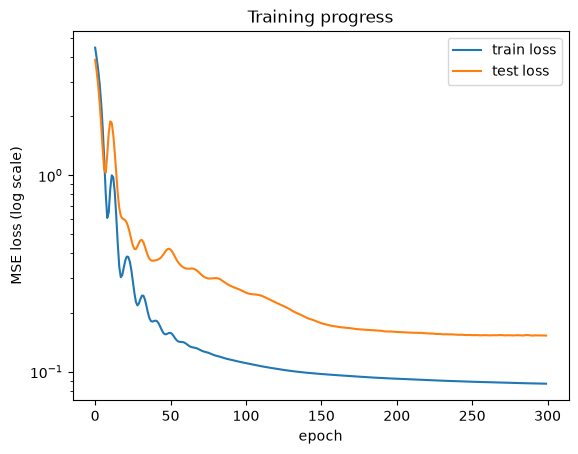

In [25]:
plt.plot(train_losses, label="train loss")
plt.plot(test_losses, label="test loss")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("MSE loss (log scale)")
plt.title("Training progress")
plt.legend()
plt.show()

📉 Both curves go down, so the network is learning things that also work on new houses. 🎉

The test loss ends up a bit **higher** than the training loss, which is normal: the model has seen the training houses hundreds of times, but never the test houses. If the training loss kept going down while the test loss went **up**, that would be **overfitting** (memorising instead of learning).

## 3.8 How good is it really?

An MSE of `0.15` doesn't mean much to a human. Let's convert it into dollars with the **RMSE** (Root Mean Squared Error): the square root of the MSE, which is in the same units as the price. Roughly speaking, it's *"by how much we're typically off"*.

To know whether that's good, we compare it with a **baseline**: a dumb "model" that always predicts the average training price, whatever the house.

In [26]:
with torch.no_grad():
    test_predictions = model(X_test_t)

# RMSE of our network (multiply by 100k to go back to dollars)
nn_rmse = torch.sqrt(loss_fn(test_predictions, y_test_t)).item() * 100_000

# RMSE of the "always predict the average" baseline
baseline_prediction = y_train_t.mean()
baseline_rmse = torch.sqrt(((y_test_t - baseline_prediction) ** 2).mean()).item() * 100_000

print(f"Baseline (always guess the average price): typical error ≈ ${baseline_rmse:,.0f}")
print(f"Our neural network:                        typical error ≈ ${nn_rmse:,.0f}")

Baseline (always guess the average price): typical error ≈ $79,888
Our neural network:                        typical error ≈ $39,069


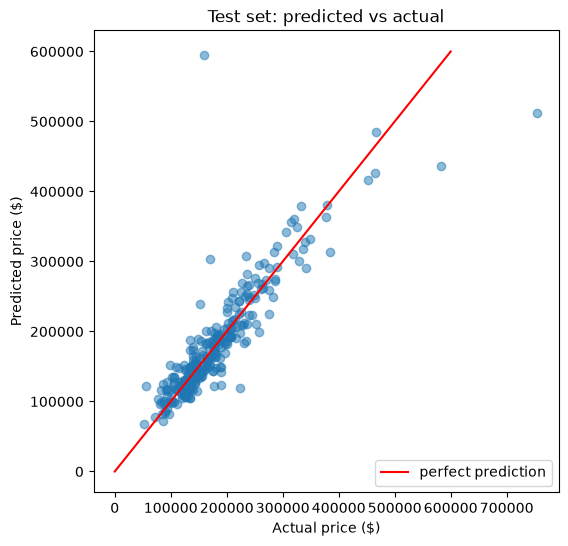

In [27]:
# Predicted vs actual price for every test house.
# A perfect model would put every point exactly on the red diagonal line.
actual = y_test_t.numpy().flatten() * 100_000
predicted = test_predictions.numpy().flatten() * 100_000

plt.figure(figsize=(6, 6))
plt.scatter(actual, predicted, alpha=0.5)
plt.plot([0, 600_000], [0, 600_000], color="red", label="perfect prediction")
plt.xlabel("Actual price ($)")
plt.ylabel("Predicted price ($)")
plt.title("Test set: predicted vs actual")
plt.legend()
plt.show()

## 3.9 Use the model on a brand-new house

Once trained, the model is just a function: features in, price out. The only thing to remember is that the new house **must be scaled with the same training mean and std**.

In [28]:
# A made-up house: quality 7/10, 1800 sq ft living area, 2-car garage,
# 1000 sq ft basement, 2 bathrooms, built in 2005
new_house = np.array([[7, 1800, 2, 1000, 2, 2005]], dtype=np.float32)

new_house_scaled = (new_house - mean) / std                       # same scaling as training!
new_house_t = torch.tensor(new_house_scaled, dtype=torch.float32)

with torch.no_grad():
    price = model(new_house_t).item() * 100_000

print(f"Predicted price: ${price:,.0f}")

Predicted price: $211,921


---
## 📝 Summary: the PyTorch recipe

```python
# 1. Prepare data  -> tensors of shape (n_samples, n_features); targets (n_samples, 1)
# 2. Define model  -> class MyNet(nn.Module) with __init__ (layers) and forward (data flow)
# 3. Choose loss + optimizer
loss_fn   = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# 4. Train
for epoch in range(n_epochs):
    optimizer.zero_grad()            # clear old gradients
    pred = model(X)                  # forward pass
    loss = loss_fn(pred, y)          # how wrong are we?
    loss.backward()                  # compute gradients (chain rule, automatically)
    optimizer.step()                 # gradient descent step

# 5. Evaluate on unseen data with torch.no_grad()
```

And remember what's going on underneath: `loss.backward()` + `optimizer.step()` is **exactly** the `dL_dw` / `w = w - lr * dL_dw` that we wrote by hand in NumPy in Part 1, just for thousands of weights at once.

---
# Part 4: Exercises 🏋️

The exercises get harder as you go:

- 🟢 **Warm-up**: small changes to code from this notebook.
- 🟡 **Intermediate**: write a bit of new code.
- 🔴 **Challenge**: put everything together.

Click **"💡 Hint"** if you get stuck, but try for a few minutes first! Wherever you see `...` in the code, that's for you to fill in.

## Exercise 1 🟢: Find the breaking point

In section 1.4 we saw that `learning_rate = 1.05` makes gradient descent on $f(w) = (w-3)^2$ explode, while `0.9` still works.

**a)** Use `gradient_descent_1d` to try different learning rates between `0.9` and `1.05`. What is the **exact** learning rate where it stops converging?

**b)** *(Think about it)* Why that value? Write down one update step and simplify $w_{\text{new}} - 3$.

<details>
<summary>💡 Hint</summary>

Substitute $f'(w) = 2(w - 3)$ into the update rule:
$w_{\text{new}} - 3 = (w_{\text{old}} - 3) - \eta \cdot 2(w_{\text{old}} - 3) = (1 - 2\eta)\,(w_{\text{old}} - 3)$.

So the distance to the minimum gets **multiplied by $(1 - 2\eta)$** at every step. When does that number make the distance shrink, and when does it make it grow?
</details>

In [ ]:
for lr in [0.9, 0.95, ...]:    # <- add more learning rates to try
    path = gradient_descent_1d(df, w_start=-4.0, learning_rate=lr, n_steps=200)
    print(f"learning rate {lr}: final w = {path[-1]:.4f}")

## Exercise 2 🟢: A valley with two bottoms

Not every function has a single minimum. Consider

$$
g(w) = w^4 - 3w^2 + w
$$

**a)** Write the derivative `dg(w)` (use the power rule: the derivative of $w^n$ is $n\,w^{n-1}$).

**b)** Run gradient descent with `learning_rate = 0.01` for 200 steps, starting from `w_start = 2` and then from `w_start = -2`. Where does each run end up?

**c)** Plot $g(w)$ for $w$ between $-2$ and $2$. Which of the two answers is the **real** (global) minimum? What does this tell you about where we start?

<details>
<summary>💡 Hint</summary>

`dg(w) = 4 * w**3 - 6 * w + 1`. Gradient descent only "feels" the ground right under its feet, so it can get stuck in the nearest valley (a **local minimum**) even if a deeper valley exists somewhere else. This is one reason why the random starting weights of a neural network matter!
</details>

In [ ]:
def g(w):
    return w**4 - 3 * w**2 + w

def dg(w):
    return ...    # <- your derivative here

# b) run gradient descent from both starting points
...

# c) plot g(w)
...

## Exercise 3 🟡: Gradient descent in 2D

Now a function of **two** parameters:

$$
h(a, b) = (a - 1)^2 + 10\,(b + 2)^2
$$

Its minimum is at $a = 1,\; b = -2$.

**a)** Compute the two partial derivatives $\frac{\partial h}{\partial a}$ and $\frac{\partial h}{\partial b}$ (treat the other variable as a constant).

**b)** Complete the loop below so that it updates **both** parameters at every step. Start at $a = -3,\; b = 2$.

**c)** Run it with `learning_rate = 0.01`, `0.05` and `0.09`. Look at the plot: why does the path **zig-zag** in the $b$ direction but not in the $a$ direction? How is this related to why we **scaled the features** in section 3.3?

<details>
<summary>💡 Hint</summary>

$\frac{\partial h}{\partial a} = 2(a - 1)$ and $\frac{\partial h}{\partial b} = 20(b + 2)$. The $b$ direction is 10× steeper than the $a$ direction, so a step size that suits $a$ is too big for $b$. Features with very different scales create exactly this kind of stretched valley.
</details>

In [ ]:
def h(a, b):
    return (a - 1) ** 2 + 10 * (b + 2) ** 2

learning_rate = 0.05
a, b = -3.0, 2.0
path = [(a, b)]

for step in range(100):
    dh_da = ...     # <- partial derivative w.r.t. a
    dh_db = ...     # <- partial derivative w.r.t. b
    a = ...         # <- update a
    b = ...         # <- update b
    path.append((a, b))

print(f"Final point: a = {a:.4f}, b = {b:.4f}   (target: a = 1, b = -2)")

# ---- Plotting code (already done for you) ----
path = np.array(path)
A, B = np.meshgrid(np.linspace(-4, 3, 200), np.linspace(-4, 3, 200))
plt.contour(A, B, h(A, B), levels=30)
plt.plot(path[:, 0], path[:, 1], "o-", color="red", markersize=3)
plt.plot(1, -2, "k*", markersize=15, label="minimum")
plt.xlabel("a")
plt.ylabel("b")
plt.title(f"2D gradient descent, learning rate = {learning_rate}")
plt.legend()
plt.show()

## Exercise 4 🟡: Fit a curve with NumPy, then check it with autograd

The data below follows a **parabola**, not a line. Our model now has **three** parameters:

$$
\hat{y} = p\,x^2 + q\,x + r
$$

**a)** Using the same reasoning as in section 1.5 (the error is $e = \hat{y} - y$, the loss is the mean of $e^2$), derive $\frac{\partial L}{\partial p}$, $\frac{\partial L}{\partial q}$ and $\frac{\partial L}{\partial r}$.

**b)** Fill in the NumPy training loop. You should get close to $p = 0.5,\; q = -1,\; r = 2$.

**c)** Check your gradient formulas with PyTorch: compute the loss with tensors that have `requires_grad=True`, call `.backward()`, and compare `.grad` with your formulas (like we did in section 2.2).

<details>
<summary>💡 Hint</summary>

Just like before, each derivative is "2 × mean of (error × derivative of $\hat{y}$ w.r.t. that parameter)":
- $\frac{\partial \hat{y}}{\partial p} = x^2$, so `dL_dp = 2 * np.mean(error * x**2)`
- $\frac{\partial \hat{y}}{\partial q} = x$
- $\frac{\partial \hat{y}}{\partial r} = 1$

If your loss blows up into `nan`, your learning rate is too big (try `0.01`).
</details>

In [ ]:
# Data (already done for you)
np.random.seed(1)
x_curve = np.random.uniform(-3, 3, 100)
y_curve = 0.5 * x_curve**2 - 1 * x_curve + 2 + np.random.normal(0, 0.5, 100)
plt.scatter(x_curve, y_curve)
plt.title("Data for exercise 4")
plt.show()

# b) NumPy gradient descent
p, q, r = 0.0, 0.0, 0.0
learning_rate = 0.01

for epoch in range(2000):
    y_pred = ...        # 1. forward pass
    error = ...
    loss = ...          # 2. loss
    dL_dp = ...         # 3. gradients
    dL_dq = ...
    dL_dr = ...
    p = ...             # 4. update
    q = ...
    r = ...

print(f"p = {p:.3f}, q = {q:.3f}, r = {r:.3f}")

In [ ]:
# c) Check your formulas with autograd at ONE point, e.g. p = 1, q = 1, r = 1
p_t = torch.tensor(1.0, requires_grad=True)
q_t = torch.tensor(1.0, requires_grad=True)
r_t = torch.tensor(1.0, requires_grad=True)
x_c = torch.tensor(x_curve, dtype=torch.float32)
y_c = torch.tensor(y_curve, dtype=torch.float32)

loss = ...          # <- MSE loss written with tensors
...                 # <- run backpropagation
print("autograd:", p_t.grad, q_t.grad, r_t.grad)

# Now compute dL_dp, dL_dq, dL_dr with YOUR NumPy formulas at p = q = r = 1 and compare
...

## Exercise 5 🟡: Become a neural-network engineer

Go back to Part 3 and try to make the house-price model **better** (a lower test RMSE). Change **one thing at a time** and write down what happens in a small table like this:

| What I changed | Test RMSE ($) | Better or worse? |
|---|---|---|
| nothing (original) | ≈ 39,000 | – |
| ... | ... | ... |

Ideas to try:
1. Change the number of neurons in the hidden layers (e.g. 8, 64, 128).
2. Add a third hidden layer (don't forget its ReLU!).
3. Change the learning rate (`0.1`, `0.001`) and the number of epochs.
4. Add more features from the dataset, e.g. `"1stFlrSF"`, `"YearRemodAdd"`, `"Fireplaces"`, `"LotArea"`, `"TotRmsAbvGrd"`. (You'll need to change the `features` list; check for missing values!)
5. Replace `Adam` with `torch.optim.SGD`. What learning rate does it need?

**Question:** Did any change make the **training** loss go down but the **test** loss go up? What is that called?

<details>
<summary>💡 Hint</summary>

To compare experiments fairly, keep `torch.manual_seed(0)` right before creating the model, so every run starts from the same random weights. When the training loss improves but the test loss gets worse, the model is **overfitting**: it is memorising the training houses instead of learning general rules.
</details>

In [ ]:
# Your experiments here (copy and modify code from Part 3)
...

## Exercise 6 🟡: Mini-batches

So far we computed the gradient using **all** training houses at once. Real-world datasets are often too big for that, so instead we split the data into small **mini-batches** (e.g. 32 houses) and take one gradient step **per mini-batch**. So one epoch now means many small steps instead of one big one.

PyTorch has two helpers for this:
- `TensorDataset(X, y)` glues inputs and targets together.
- `DataLoader(dataset, batch_size=32, shuffle=True)` hands you random mini-batches, one at a time.

**a)** Complete the training loop below. You need an **inner loop** over the batches.

**b)** Train for 50 epochs. How does the test RMSE compare with full-batch training? How many weight updates happen per epoch?

<details>
<summary>💡 Hint</summary>

```python
for X_batch, y_batch in train_loader:
    optimizer.zero_grad()
    loss = loss_fn(model(X_batch), y_batch)
    loss.backward()
    optimizer.step()
```

The number of updates per epoch is `len(train_loader)` = number of training houses ÷ batch size (rounded up).
</details>

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

torch.manual_seed(0)
model = HousePriceNet(n_features=len(features))
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    for X_batch, y_batch in train_loader:
        ...    # <- the 5 training lines, using X_batch and y_batch

    with torch.no_grad():
        test_loss = loss_fn(model(X_test_t), y_test_t)
    if epoch % 10 == 0:
        print(f"epoch {epoch} | test loss = {test_loss.item():.4f}")

# Print the final test RMSE in dollars
...

## Exercise 7 🔴: Classification with a neural network

So far we predicted a **number** (regression). Now we'll predict a **category** (classification).

The data below is the famous **spiral dataset**: points in 2D belonging to **3 classes** (3 coloured spiral arms). A straight line can't separate them, so you need a neural network!

**Your task:** build and train a network that classifies the points.

Differences from regression:

| | Regression (Part 3) | Classification (here) |
|---|---|---|
| Output layer | 1 neuron (the price) | **3 neurons**, one score per class |
| Loss | `nn.MSELoss()` | `nn.CrossEntropyLoss()` |
| Target `y` | floats, shape `(n, 1)` | **integers** `0, 1, 2`, shape `(n,)`, dtype `torch.long` |
| Prediction | the output itself | the class with the **highest score**: `output.argmax(dim=1)` |

⚠️ `nn.CrossEntropyLoss` applies softmax **internally**, so **do not** put a softmax at the end of your network. Just output the raw scores (called **logits**).

**Steps:**
1. Convert `X_spiral` and `y_spiral` to tensors (watch the dtypes!).
2. Build a network: `2 inputs → 64 → ReLU → 64 → ReLU → 3 outputs`.
3. Train it with `Adam(lr=0.01)` for ~1000 epochs using `CrossEntropyLoss`.
4. Print the **accuracy** every 100 epochs: `(predictions == y).float().mean()`.
5. Use the provided `plot_decision_boundary(model)` to see what your network learned. 🎨

🎯 **Goal:** more than 90% accuracy.

<details>
<summary>💡 Hint</summary>

```python
X_s = torch.tensor(X_spiral, dtype=torch.float32)
y_s = torch.tensor(y_spiral, dtype=torch.long)        # class labels must be integers

clf = nn.Sequential(nn.Linear(2, 64), nn.ReLU(),
                    nn.Linear(64, 64), nn.ReLU(),
                    nn.Linear(64, 3))
loss_fn = nn.CrossEntropyLoss()
```
The training loop is exactly the same 5 lines as always!
</details>

**Bonus questions:**
- What accuracy do you get with **no hidden layer** (`nn.Linear(2, 3)` only)? Plot its decision boundary. Why is it so bad?
- What happens if you remove the ReLUs but keep the hidden layers?

In [ ]:
# ---- Data + plotting helper (already done for you) ----
def make_spiral_data(points_per_class=100, n_classes=3, seed=0):
    rng = np.random.default_rng(seed)
    X = np.zeros((points_per_class * n_classes, 2), dtype=np.float32)
    y = np.zeros(points_per_class * n_classes, dtype=np.int64)
    for c in range(n_classes):
        idx = range(points_per_class * c, points_per_class * (c + 1))
        radius = np.linspace(0.0, 1, points_per_class)
        angle = np.linspace(c * 4, (c + 1) * 4, points_per_class) + rng.normal(0, 0.2, points_per_class)
        X[idx] = np.c_[radius * np.sin(angle * 2.5), radius * np.cos(angle * 2.5)]
        y[idx] = c
    return X, y


def plot_decision_boundary(model):
    # Colours every point of the plane by the class the model predicts there
    xx, yy = np.meshgrid(np.linspace(-1.1, 1.1, 300), np.linspace(-1.1, 1.1, 300))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        zz = model(grid).argmax(dim=1).numpy().reshape(xx.shape)
    plt.contourf(xx, yy, zz, alpha=0.3, cmap="brg")
    plt.scatter(X_spiral[:, 0], X_spiral[:, 1], c=y_spiral, cmap="brg", s=10)
    plt.title("Decision boundary")
    plt.show()


X_spiral, y_spiral = make_spiral_data()
plt.scatter(X_spiral[:, 0], X_spiral[:, 1], c=y_spiral, cmap="brg", s=10)
plt.title("Spiral data: 3 classes")
plt.show()

In [ ]:
# ---- Your code here ----
# 1. tensors
...

# 2. model
...

# 3. loss + optimizer
...

# 4. training loop with accuracy printouts
...

# 5. plot_decision_boundary(your_model)

## Exercise 8 🔴🔴: Bonus. A neural network with NO PyTorch

The ultimate test: train a small neural network using **only NumPy**, writing backpropagation yourself. The notes in `back_prop_notes.pdf` will help.

**Task:** learn the curve $y = \sin(x)$ with a network that has **1 hidden layer of 16 neurons with ReLU**:

$$
\underbrace{z_1 = X W_1 + b_1}_{\text{shape } (n,16)} \;\rightarrow\; \underbrace{a_1 = \text{ReLU}(z_1)}_{(n,16)} \;\rightarrow\; \underbrace{\hat{y} = a_1 W_2 + b_2}_{(n,1)} \;\rightarrow\; L = \text{mean}\big((\hat{y} - y)^2\big)
$$

The backward pass is the chain rule, going from the loss back to the start. Every arrow above becomes one line of code:

| Gradient | Formula | Shape |
|---|---|---|
| $\partial L / \partial \hat{y}$ | `2 * (y_pred - y) / n` | `(n, 1)` |
| $\partial L / \partial W_2$ | `a1.T @ dL_dy_pred` | `(16, 1)` |
| $\partial L / \partial b_2$ | `dL_dy_pred.sum(axis=0)` | `(1,)` |
| $\partial L / \partial a_1$ | `dL_dy_pred @ W2.T` | `(n, 16)` |
| $\partial L / \partial z_1$ | `dL_da1 * (z1 > 0)`  ← ReLU derivative! | `(n, 16)` |
| $\partial L / \partial W_1$ | `X.T @ dL_dz1` | `(1, 16)` |
| $\partial L / \partial b_1$ | `dL_dz1.sum(axis=0)` | `(16,)` |

**Steps:** initialise the weights randomly (small numbers, e.g. `0.5 * np.random.randn(...)`), write the forward pass, the backward pass and the update, and train for a few thousand epochs. Plot your network's predictions on top of the true sine curve.

**Extra challenge:** build the same network in PyTorch, copy *your* starting weights into it, and check that `loss.backward()` gives the same gradients as your NumPy code after one step.

<details>
<summary>💡 Hint</summary>

A good learning rate is around `0.05`. If the curve looks like a straight line, train for longer, or check the ReLU derivative `(z1 > 0)` in the backward pass. Always print the **shapes** of your arrays when something doesn't work: 90% of bugs are shape bugs!
</details>

In [ ]:
np.random.seed(0)
X_sin = np.linspace(-3, 3, 200).reshape(-1, 1)     # shape (200, 1)
y_sin = np.sin(X_sin)                               # shape (200, 1)

# Initialise the parameters
W1 = 0.5 * np.random.randn(1, 16)
b1 = np.zeros(16)
W2 = 0.5 * np.random.randn(16, 1)
b2 = np.zeros(1)

learning_rate = 0.05

for epoch in range(5000):
    # ---- forward pass ----
    z1 = ...
    a1 = ...
    y_pred = ...
    loss = ...

    # ---- backward pass (see the table above) ----
    ...

    # ---- update ----
    ...

    if epoch % 500 == 0:
        print(f"epoch {epoch} | loss = {loss:.4f}")

# Plot your predictions vs the true curve
...

---
## 🎉 Well done!

If you made it through the exercises, you now understand what's **really** going on inside every neural network:

1. A **forward pass** makes predictions.
2. A **loss** measures how wrong they are.
3. **Backpropagation** (the chain rule) computes how each weight affects the loss.
4. **Gradient descent** nudges every weight a little bit downhill.
5. **Repeat** thousands of times.

Everything else (bigger networks, images, text, ChatGPT-style models) is built on these same 5 ideas. 🚀